In [1]:
import pandas as pd, numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
pd.options.display.max_rows = 999
pd.options.display.max_columns = 90

### Load the data (csv)

In [2]:
df = pd.read_csv("data/proj_machine_readings.csv", parse_dates=["timestamp"])
df.head()

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


### (1) Initial Data Understanding and Insights
Per the Problem Statement, the target is `maintenance_required` (0 = no, 1 = yes). Goal: an alert system that flags machines due for maintenance, build >= 3 models and find which features matter most. `machine_status`, `anomaly_flag`, `predicted_remaining_life`, `failure_type` and `downtime_risk` are **derived columns**.

In [3]:
#
# *** Insights from running .info() ****
#
# 100,000 rows x 13 columns. Only `temperature` has nulls (about 14%).
# timestamp is already datetime. machine_id, machine_status, anomaly_flag, maintenance_required are integer codes
# (categorical in meaning). failure_type is a string category. downtime_risk is float but looks like a 0/1 flag.
#
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   timestamp                 100000 non-null  datetime64[us]
 1   machine_id                100000 non-null  int64         
 2   temperature               86000 non-null   float64       
 3   vibration                 100000 non-null  float64       
 4   humidity                  100000 non-null  float64       
 5   pressure                  100000 non-null  float64       
 6   energy_consumption        100000 non-null  float64       
 7   machine_status            100000 non-null  int64         
 8   anomaly_flag              100000 non-null  int64         
 9   predicted_remaining_life  100000 non-null  int64         
 10  failure_type              100000 non-null  str           
 11  downtime_risk             100000 non-null  float64       
 12  maintenance_re

In [4]:
print("duplicate rows:", df.duplicated().sum())
print("timestamp steps != 1 min:", (df["timestamp"].diff().dropna() != pd.Timedelta("1min")).sum())
df.describe().T

duplicate rows: 0
timestamp steps != 1 min: 0


,count,mean,min,25%,50%,75%,max,std
timestamp,100000,2025-02-04 17:19:30,2025-01-01 00:00:00,2025-01-18 08:39:45,2025-02-04 17:19:30,2025-02-22 01:59:15,2025-03-11 10:39:00,NaN
machine_id,100000.0,25.49933,1.0,13.0,25.0,38.0,50.0,14.389439
temperature,86000.0,75.03441,35.55,68.28,75.09,81.78,121.94,10.036257
vibration,100000.0,43.324232,-106.98,37.22,48.635,59.25,113.8,29.134306
humidity,100000.0,54.995401,30.0,42.52,54.98,67.5,80.0,14.43796
pressure,100000.0,3.000405,1.0,2.0,3.01,4.0,5.0,1.152399
energy_consumption,100000.0,2.747064,0.5,1.63,2.74,3.87,5.0,1.297865
machine_status,100000.0,1.00205,0.0,1.0,1.0,1.0,2.0,0.446193
anomaly_flag,100000.0,0.08916,0.0,0.0,0.0,0.0,1.0,0.284976
predicted_remaining_life,100000.0,234.26916,1.0,97.0,230.0,365.0,499.0,150.063062


#### Column By Column Investigation and Insights

##### 1. Target Column: maintenance_required

maintenance_required
0    80303
1    19697
Name: count, dtype: int64

maintenance_required
0    0.80303
1    0.19697
Name: proportion, dtype: float64

<Axes: xlabel='maintenance_required'>

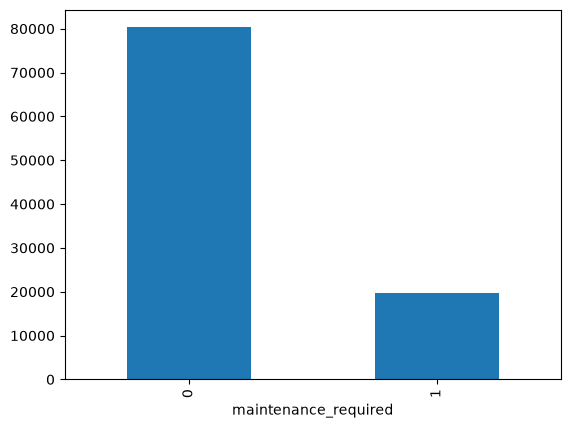

In [5]:
#
# **** Insights ******
# Only 2 values, so this is a binary classification problem.
# Moderate class imbalance (about 19.7% need maintenance). Always predicting 0 scores ~80% accuracy,
# so accuracy is a weak metric; the business cost is a MISSED maintenance (unscheduled downtime), so recall on
# class 1 together with precision / PR-AUC matter most. Consider class weights.
#
display(df["maintenance_required"].value_counts())
display(df["maintenance_required"].value_counts(normalize=True))
df["maintenance_required"].value_counts().plot(kind="bar")

##### 2. temperature

null share: 0.14


,maintenance_required,anomaly_flag,machine_status
temperature,,,
False,0.197488,0.089395,1.002174
True,0.193786,0.087714,1.001286


<Axes: >

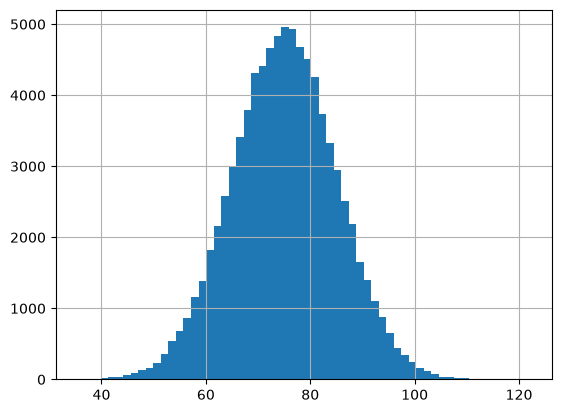

In [6]:
#
# Insights:
# 14% null. Check whether the nulls are random or related to other columns.
# Values range roughly 50-100, with a cluster of values above 90.
#
print("null share:", df["temperature"].isna().mean().round(4))
display(df.groupby(df["temperature"].isna())[["maintenance_required", "anomaly_flag", "machine_status"]].mean())
df["temperature"].hist(bins=60)

In [7]:
#
# Nulls are not more common for any failure type, so they look random.
# BUT about 1,228 anomalies have no temperature, so the nulls hide part of the main anomaly signal.
#
display(df["temperature"].isna().groupby(df["failure_type"]).mean())
print("anomalies with null temperature:", (df["temperature"].isna() & (df["anomaly_flag"] == 1)).sum())

failure_type
Electrical Fault    0.142012
Normal              0.140339
Overheating         0.141277
Pressure Drop       0.124937
Vibration Issue     0.138063
Name: temperature, dtype: float64

anomalies with null temperature: 1228


##### 3. vibration

negative share: 0.067 | min: -106.98


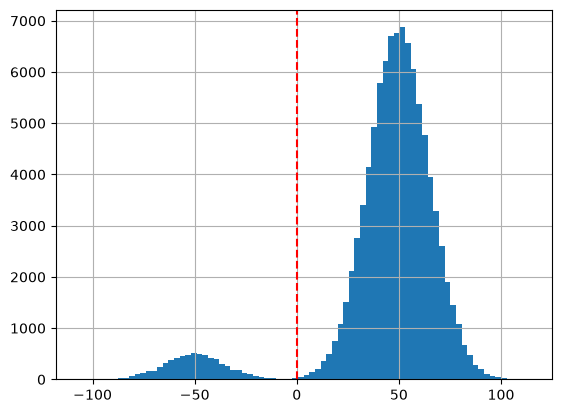

In [8]:
#
# Insights:
# About 6.7% of values are negative. Vibration amplitude should not be negative.
# It could be a sensor offset or a data-generation artefact. We keep the values (the >80 rule is unaffected),
# add an indicator column, and flag this to the data owner.
#
print("negative share:", (df["vibration"] < 0).mean().round(4), "| min:", df["vibration"].min())
df["vibration"].hist(bins=80); plt.axvline(0, color="r", ls="--")

##### 4. humidity, pressure, energy_consumption

array([[<Axes: title={'center': 'humidity'}>,
        <Axes: title={'center': 'pressure'}>,
        <Axes: title={'center': 'energy_consumption'}>]], dtype=object)

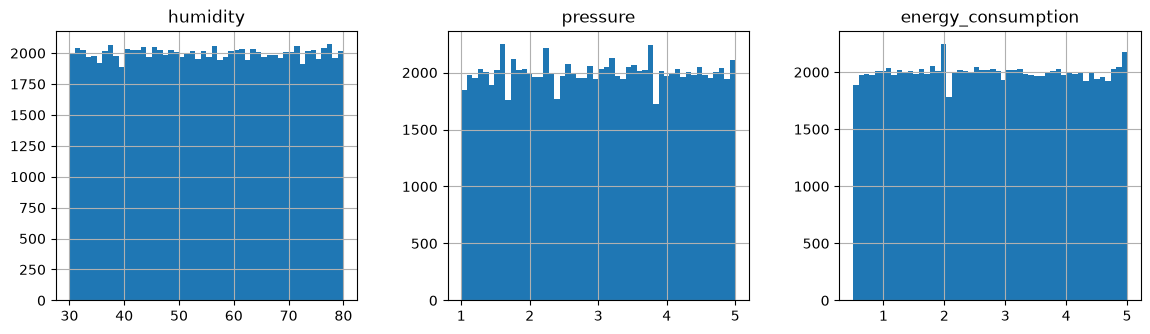

In [9]:
#
# Insights:
# No nulls. Spread evenly across their ranges, no obvious outliers.
# Likely low predictive value for maintenance_required (checked in the bivariate section below).
#
df[["humidity", "pressure", "energy_consumption"]].hist(bins=50, figsize=(14, 3.5), layout=(1, 3))

##### 5. machine_id and machine_status

In [10]:
#
# Insights:
# 50 machines with about 2,000 readings each, so rows are NOT independent (same machine repeated) -> use a
# group-aware split later. machine_status: 1 (80%), 0 (10%), 2 (10%); status 2 behaves like the failure state.
#
display(df["machine_id"].nunique(), df["machine_id"].value_counts().describe())
display(df["machine_status"].value_counts(normalize=True))

50

count      50.000000
mean     2000.000000
std        51.673228
min      1906.000000
25%      1956.250000
50%      2002.500000
75%      2042.500000
max      2092.000000
Name: count, dtype: float64

machine_status
1    0.80091
2    0.10057
0    0.09852
Name: proportion, dtype: float64

##### 6. failure_type

In [11]:
#
# Insights:
# 5 categories, ~92% "Normal". Failures only occur when machine_status = 2.
# About 1,956 status-2 rows are labelled "Normal" -> labelling inconsistency, noted, not changed.
#
display(df["failure_type"].value_counts())
pd.crosstab(df["machine_status"], df["failure_type"])

failure_type
Normal              91899
Vibration Issue      3129
Overheating          1989
Pressure Drop        1969
Electrical Fault     1014
Name: count, dtype: int64

failure_type,Electrical Fault,Normal,Overheating,Pressure Drop,Vibration Issue
machine_status,,,,,
0,0,9852,0,0,0
1,0,80091,0,0,0
2,1014,1956,1989,1969,3129


##### 7. predicted_remaining_life, downtime_risk, maintenance_required (possible leakage)

downtime_risk == anomaly_flag: 0.9999
maintenance rule matches: 1.0
max remaining life of flagged rows: 49


<Axes: >

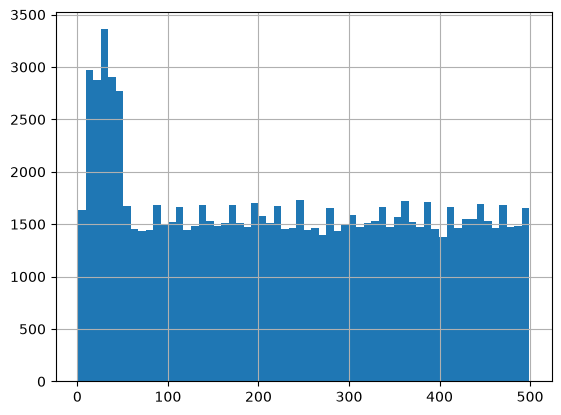

In [12]:
#
# Insights:
# maintenance_required is EXACTLY: anomaly_flag OR machine_status==2 OR predicted_remaining_life<20.
# So those three derived columns reproduce the target (100% match) - a model using them just reads the formula.
# downtime_risk equals anomaly_flag (~99.99%), so it is the same leak. failure_type only occurs when status==2.
# The Problem Statement says "some columns are derived", so the honest model uses raw sensors (+ machine_id/time);
# derived columns are only used to EXPLAIN the target, not to predict it.
#
print("downtime_risk == anomaly_flag:", (df["downtime_risk"] == df["anomaly_flag"]).mean().round(4))
rule = ((df["anomaly_flag"] == 1) | (df["machine_status"] == 2) | (df["predicted_remaining_life"] < 20)).astype(int)
print("maintenance rule matches:", (rule == df["maintenance_required"]).mean())
print("max remaining life of flagged rows:", df.loc[df["anomaly_flag"] == 1, "predicted_remaining_life"].max())
df["predicted_remaining_life"].hist(bins=60)

##### 8. timestamp

2025-01-01 00:00:00 2025-03-11 10:39:00


<Axes: title={'center': 'Weekly maintenance rate'}, xlabel='timestamp'>

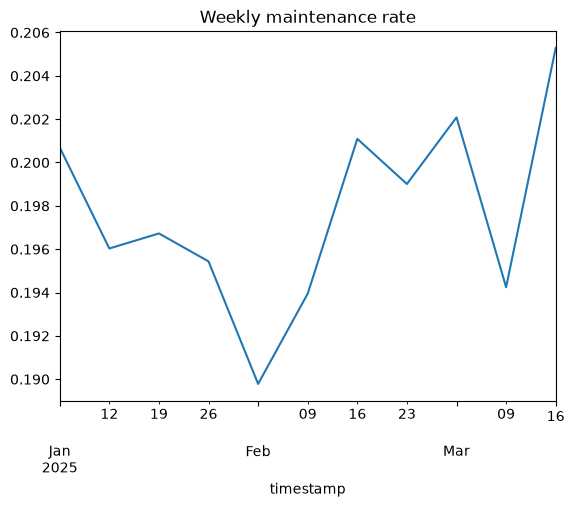

In [13]:
#
# Insights:
# 2025-01-01 to 2025-03-11, one row per minute with no gaps. Time-ordered data -> chronological split needed.
#
print(df["timestamp"].min(), df["timestamp"].max())
df.set_index("timestamp")["maintenance_required"].resample("W").mean().plot(title="Weekly maintenance rate")

### (2) Column by Column data cleaning
Working on a copy so the raw frame stays untouched.

In [14]:
dfc = df.copy()

#### 1. Types

In [15]:
#
# downtime_risk is 0/1 stored as float. machine_id / machine_status / failure_type are categories in meaning.
#
dfc["downtime_risk"] = dfc["downtime_risk"].round().astype(int)
dfc["machine_id"] = dfc["machine_id"].astype("category")
dfc["machine_status"] = dfc["machine_status"].astype("category")
dfc["failure_type"] = dfc["failure_type"].astype("category")
dfc.dtypes

timestamp                   datetime64[us]
machine_id                        category
temperature                        float64
vibration                          float64
humidity                           float64
pressure                           float64
energy_consumption                 float64
machine_status                    category
anomaly_flag                         int64
predicted_remaining_life             int64
failure_type                      category
downtime_risk                        int64
maintenance_required                 int64
dtype: object

#### 2. temperature (nulls)

In [16]:
#
# Nulls look random but hide anomalies, so we add an indicator column and do NOT impute here.
# The fill value (e.g. median) must be learned from the training set only, so imputation is done after the
# train/validation/test split in preprocessing. Imputing now would leak test-set information.
#
dfc["temperature_missing"] = dfc["temperature"].isna().astype(int)
dfc["temperature_missing"].value_counts()

temperature_missing
0    86000
1    14000
Name: count, dtype: int64

#### 3. vibration (negatives)

In [17]:
#
# Keep original values, add an indicator. Revisit if the data owner says the negatives are errors.
#
dfc["vibration_negative"] = (dfc["vibration"] < 0).astype(int)
dfc["vibration_negative"].value_counts()

vibration_negative
0    93297
1     6703
Name: count, dtype: int64

#### 4. failure_type vs machine_status

In [18]:
#
# About 1,956 status-2 rows are "Normal". With no source of truth, keep as-is and record as a data quality issue.
#
dfc.loc[(dfc["machine_status"] == 2) & (dfc["failure_type"] == "Normal")].shape[0]

1956

### 3. Bivariate Analysis

#### 3.1 Heatmap and Pearson's correlation

<Axes: >

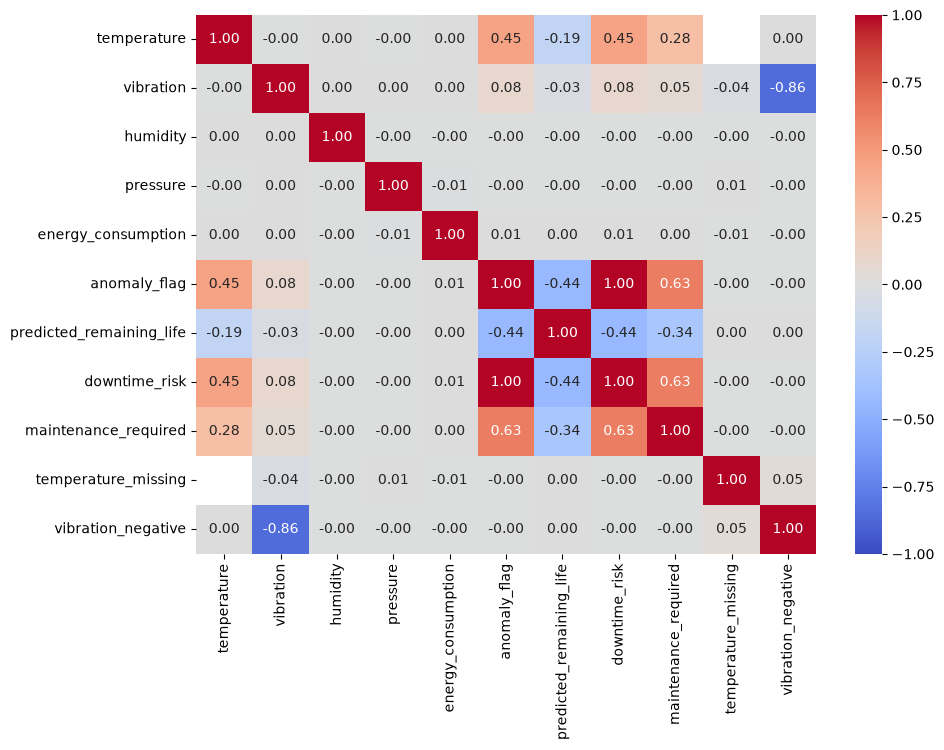

In [19]:
#
# **** Insights ****
# Derived columns (anomaly_flag, downtime_risk, predicted_remaining_life, machine_status) correlate with the target
# (leakage). Of the raw sensors temperature (~0.28) is clearly related and vibration weakly (~0.05).
# Humidity, pressure, energy are ~ 0.
# Near-zero Pearson does not prove "no relationship" (the temperature effect is a threshold, not linear), so we
# also plot the rates below.
#
num = dfc.select_dtypes("number")
plt.figure(figsize=(10, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

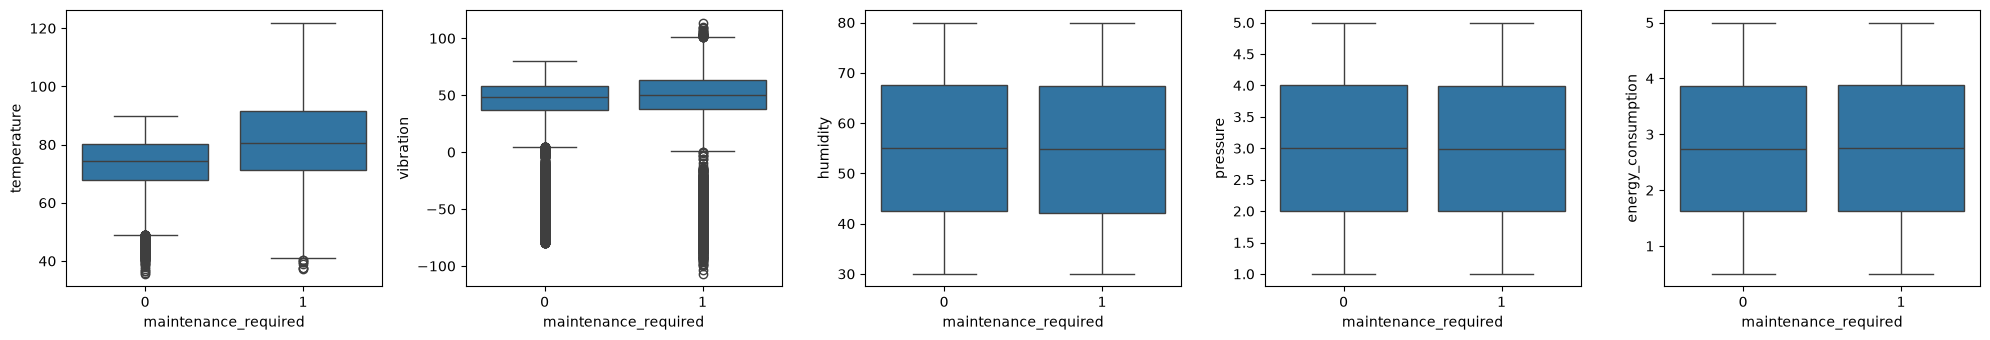

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, c in zip(axes, ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]):
    sns.boxplot(data=dfc, x="maintenance_required", y=c, ax=ax)
plt.tight_layout()

maintenance when above a cutoff: 1.0
maintenance when below both (temperature known): 0.12


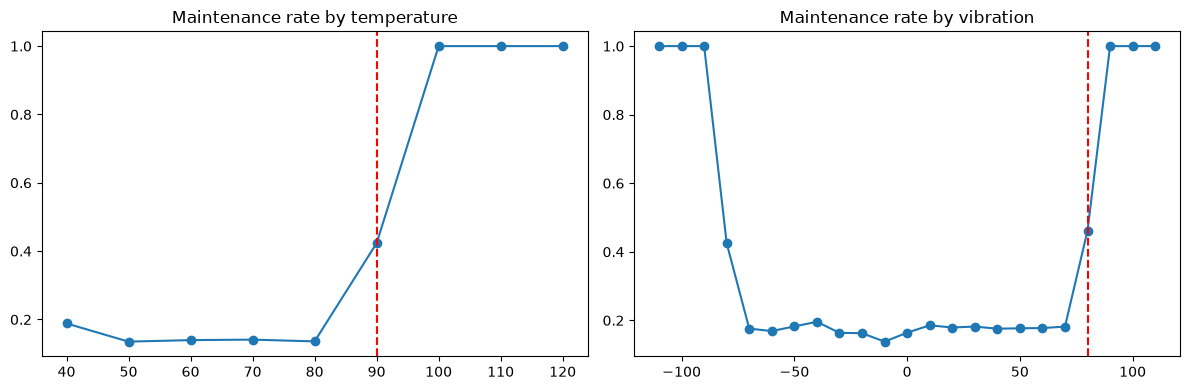

In [21]:
#
# Threshold effect: above temperature 90 or vibration 80 maintenance is ~100%. Below, it is still ~12% because
# machine_status==2 and low remaining life (not visible in the sensors) also trigger it. So sensors alone can
# only explain part of the target.
#
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c, cut in zip(axes, ["temperature", "vibration"], [90, 80]):
    rate = dfc.dropna(subset=[c]).groupby(dfc[c].round(-1))["maintenance_required"].mean()
    ax.plot(rate.index, rate.values, marker="o"); ax.axvline(cut, color="r", ls="--"); ax.set_title(f"Maintenance rate by {c}")
plt.tight_layout()
hit = (dfc["temperature"] > 90) | (dfc["vibration"] > 80)
print("maintenance when above a cutoff:", dfc.loc[hit, "maintenance_required"].mean().round(4))
print("maintenance when below both (temperature known):", dfc.loc[~hit & dfc["temperature"].notna(), "maintenance_required"].mean().round(4))

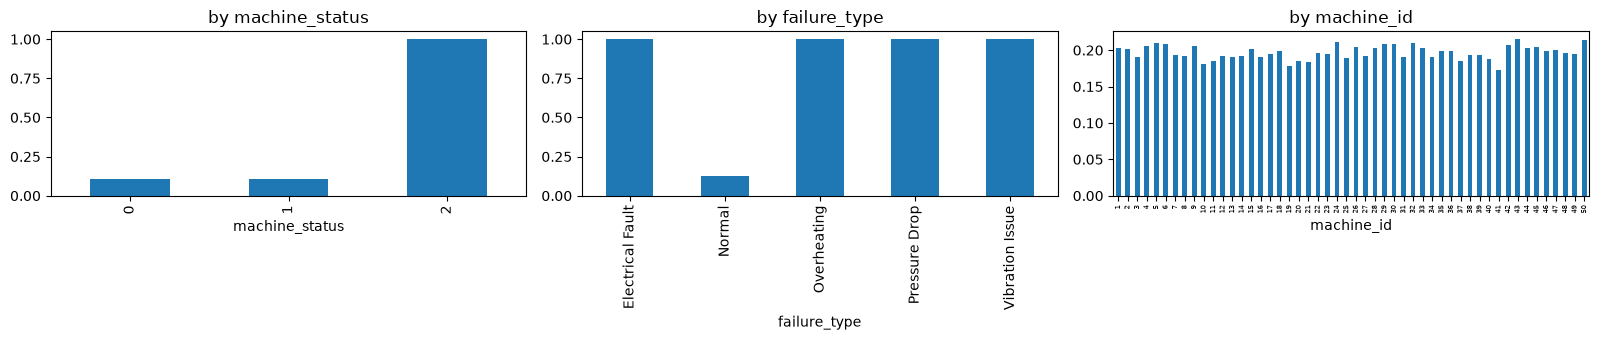

In [22]:
#
# Categorical vs target: maintenance rate by machine_status, failure_type and machine_id.
#
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
dfc.groupby("machine_status", observed=True)["maintenance_required"].mean().plot.bar(ax=axes[0], title="by machine_status")
dfc.groupby("failure_type", observed=True)["maintenance_required"].mean().plot.bar(ax=axes[1], title="by failure_type")
dfc.groupby("machine_id", observed=True)["maintenance_required"].mean().plot.bar(ax=axes[2], title="by machine_id")
axes[2].tick_params(axis="x", labelsize=5)
plt.tight_layout()

### 4. Feature Engineering

Time features, then a candidate feature list with the leaky columns excluded, then bivariate analysis again.

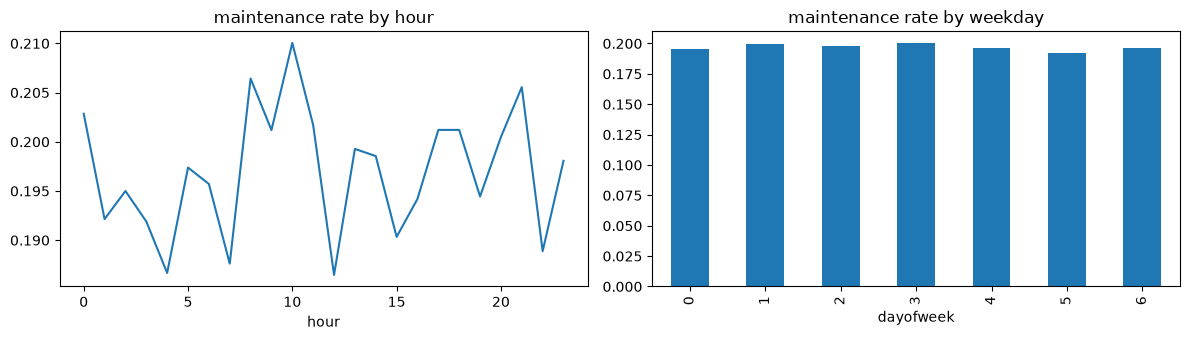

In [23]:
#
# Time features from timestamp. Anomaly rates were flat by week earlier, so we check hour and weekday.
#
dfc["hour"] = dfc["timestamp"].dt.hour
dfc["dayofweek"] = dfc["timestamp"].dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
dfc.groupby("hour")["maintenance_required"].mean().plot(ax=axes[0], title="maintenance rate by hour")
dfc.groupby("dayofweek")["maintenance_required"].mean().plot.bar(ax=axes[1], title="maintenance rate by weekday")
plt.tight_layout()

In [24]:
#
# Derived columns excluded because they reproduce maintenance_required (kept only for explanation):
#
LEAKY = ["anomaly_flag", "downtime_risk", "predicted_remaining_life", "machine_status", "failure_type"]
FEATURES = ["temperature", "vibration", "humidity", "pressure", "energy_consumption", "machine_id",
            "temperature_missing", "vibration_negative", "hour", "dayofweek"]
print("dropped as leakage:", LEAKY)
print("candidate features:", FEATURES)
tmp = dfc[FEATURES + ["maintenance_required"]].copy()
tmp["machine_id"] = tmp["machine_id"].astype(int)
tmp.corr()["maintenance_required"].sort_values()

dropped as leakage: ['anomaly_flag', 'downtime_risk', 'predicted_remaining_life', 'machine_status', 'failure_type']
candidate features: ['temperature', 'vibration', 'humidity', 'pressure', 'energy_consumption', 'machine_id', 'temperature_missing', 'vibration_negative', 'hour', 'dayofweek']


humidity               -0.003815
temperature_missing    -0.003230
dayofweek              -0.002391
pressure               -0.001945
vibration_negative     -0.000733
energy_consumption      0.001384
hour                    0.002134
machine_id              0.002537
vibration               0.051313
temperature             0.282663
maintenance_required    1.000000
Name: maintenance_required, dtype: float64

### Summary of insights
- **Target:** `maintenance_required` (Problem Statement), binary, 19.7% positive.
- **Leakage:** it equals `anomaly_flag` OR `machine_status == 2` OR `predicted_remaining_life < 20`. Those derived columns (and `downtime_risk`, `failure_type`) are excluded as features and used only to explain the target.
- **Sensors:** temperature > 90 or vibration > 80 means maintenance ~100% of the time; below that it is still ~12% (status 2 / low life are not visible in the sensors), so expect a ceiling on sensor-only models.
- **Data quality:** 14% missing temperature, 6.7% negative vibration, ~1,956 status-2 rows labelled Normal.
- **No machine or time effect**; rows repeat per machine and are time-ordered, so split by time and by machine group.
- **Likely synthetic data.**
- **Next:** build >= 3 models (e.g. logistic regression, random forest, gradient boosting), judged on recall/PR-AUC against a majority-class baseline, and report feature importance.